# 04 – Backtest, benchmarks and performance

A hypothetical backtest of the **current** weights from 2019 onwards, compared with the main benchmark (50% MSCI World / 35% Bloomberg Commodity / 15% MSCI EM IMI) and the look-through benchmark per pie, followed by a reconciliation with the Archief sheet of the workbook.

**Read this first.** Everything before 31-10-2026 is a backtest of today's selection. It contains hindsight (look-ahead and selection bias): the positions were chosen knowing how the world turned out. The results describe how this portfolio *would have behaved*, not how well it was *managed*.

**Methodological choices**
- Returns: daily total returns in EUR (Yahoo `Adj Close`, ECB rates), proxies before fund launch as documented in notebook 02.
- Positions without data yet: their weight is redistributed pro rata **within the same pie**, so pie weights (27/13/10/18/17/15) and the 50/50 block split stay intact.
- Two strategies: **monthly rebalanced** to target weights, and **buy-and-hold**. Both also rebalance on the few days when a new position enters the data (the investable universe changes).
- Risk-free rate: €STR (ECB). Before its launch (October 2019) the first €STR value is used.
- Sub-periods: 2019–2021, 2022 (rate shock), 2023–now.

## Setup

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
PROCESSED_DIR = Path("../data/processed")
DATA_PATH = Path("../data/raw/portfolio_20261031.xlsx")
DB_PATH = PROCESSED_DIR / "portfolio.db"

TRADING_DAYS = 252
HICP_URL = (
    "https://data-api.ecb.europa.eu/service/data/ICP/M.U2.N.000000.4.INX"
    "?format=csvdata&startPeriod=2018-12"
)
ESTR_URL = (
    "https://data-api.ecb.europa.eu/service/data/EST/B.EU000A2X2A25.WT"
    "?format=csvdata&startPeriod=2019-01-01"
)

MAIN_BENCHMARK = {"IWDA": 0.50, "CMOD": 0.35, "EIMI": 0.15}
PIE_BENCHMARKS = {
    "Kwaliteit": {"IWQU": 1.0},
    "Thematisch": {"IWDA": 1.0},
    "AI Boom": {"AIQU": 1.0},
    "Energie": {"WNRG": 0.70, "NUCL": 0.30},
    "Mijnbouw": {"GDX": 0.65, "COPX": 0.35},
    "Multipolaire Wereldorde": {"EIMI": 1.0},
}
SUBPERIODS = {
    "2019-2021": ("2019-01-01", "2021-12-31"),
    "2022": ("2022-01-01", "2022-12-31"),
    "2023-now": ("2023-01-01", "2100-01-01"),
}

## Load data

In [3]:
holdings = pd.read_parquet(PROCESSED_DIR / "holdings.parquet")
returns_total = pd.read_parquet(PROCESSED_DIR / "returns_total_eur.parquet")
returns_price = pd.read_parquet(PROCESSED_DIR / "returns_price_eur.parquet")

target = holdings.set_index("ticker")["weight_in_portfolio"]
pie_of = holdings.set_index("ticker")["pie"]

missing = set(target.index) - set(returns_total.columns)
assert not missing, f"No returns for: {missing}"
print(returns_total.shape)
returns_total.index.min(), returns_total.index.max()

(2025, 63)


(Timestamp('2019-01-02 00:00:00'), Timestamp('2026-10-30 00:00:00'))

## Risk-free rate (€STR)

€STR is an annualised overnight rate in percent, act/360. The daily risk-free return between two trading days is the rate times the number of calendar days in between, divided by 360.

In [4]:
estr_raw = pd.read_csv(ESTR_URL)
estr = estr_raw.set_index(pd.to_datetime(estr_raw["TIME_PERIOD"]))["OBS_VALUE"].sort_index()

dates = returns_total.index
estr_daily = estr.reindex(dates.union(estr.index)).ffill().bfill().reindex(dates)
calendar_days = dates.to_series().diff().dt.days.fillna(1)
rf = estr_daily / 100 * calendar_days / 360

print(f"€STR from {estr.index.min().date()}, last value {estr.iloc[-1]:.3f}%")
rf.resample("YE").sum().round(4)

€STR from 2019-10-01, last value 2.441%


Date
2019-12-31   -0.0055
2020-12-31   -0.0056
2021-12-31   -0.0058
2022-12-31   -0.0001
2023-12-31    0.0324
2024-12-31    0.0373
2025-12-31    0.0221
2026-12-31    0.0175
Freq: YE-DEC, dtype: float64

## Backtest engine

`rebalance_weights` sets target weights, redistributing the weight of positions without data within their group (pie). `backtest` lets weights drift with returns between rebalance dates. Weights set at the close of day *t* apply to the returns of day *t+1*, so no return is used before it is known.

In [5]:
def rebalance_weights(target, groups, available):
    """Target weights with each group's weight redistributed over its available members."""
    w = target[available]
    if w.empty:
        return w
    group_target = target.groupby(groups).sum()
    group_available = w.groupby(groups[w.index]).sum()
    scale = (group_target / group_available).reindex(groups[w.index].values).values
    return w * scale


def backtest(returns, target, groups, rebalance_dates):
    """Daily returns of a portfolio that drifts between rebalance dates."""
    returns = returns[target.index]
    started = returns.notna().cummax()
    rebalance_dates = set(rebalance_dates)
    out = pd.Series(np.nan, index=returns.index)
    w = None
    for date, row in returns.iterrows():
        if w is not None and w.sum() > 0:
            r = row[w.index].fillna(0.0)
            out[date] = (w * r).sum() / w.sum()
            w = w * (1 + r)
        if w is None or w.sum() == 0 or date in rebalance_dates:
            available = started.loc[date][started.loc[date]].index
            w = rebalance_weights(target, groups, available)
    return out

In [6]:
def month_ends(index):
    """Last trading day of each month in a DatetimeIndex."""
    return index.to_series().groupby(index.to_period("M")).max().tolist()


def universe_changes(returns):
    """Dates on which at least one column gets its first return."""
    started = returns.notna().cummax()
    changed = started.astype(int).diff().fillna(0).gt(0).any(axis=1)
    return returns.index[changed].tolist()

## Portfolio and benchmark returns

In [7]:
holding_returns = returns_total[target.index]
new_data_dates = universe_changes(holding_returns)
print(f"Universe changes on {len(new_data_dates)} dates:", [d.date() for d in new_data_dates])

port_monthly = backtest(holding_returns, target, pie_of, month_ends(dates) + new_data_dates)
port_buy_hold = backtest(holding_returns, target, pie_of, new_data_dates)

bench_target = pd.Series(MAIN_BENCHMARK)
bench_groups = pd.Series("benchmark", index=bench_target.index)
bench_monthly = backtest(returns_total, bench_target, bench_groups, month_ends(dates))

series = pd.DataFrame({
    "Portfolio (monthly rebalanced)": port_monthly,
    "Portfolio (buy-and-hold)": port_buy_hold,
    "Main benchmark (monthly)": bench_monthly,
    "MSCI World (IWDA)": returns_total["IWDA"],
})
series.dropna().shape

Universe changes on 10 dates: [datetime.date(2019, 1, 3), datetime.date(2019, 1, 4), datetime.date(2019, 4, 11), datetime.date(2019, 6, 21), datetime.date(2019, 9, 25), datetime.date(2021, 5, 7), datetime.date(2022, 1, 20), datetime.date(2024, 3, 28), datetime.date(2024, 4, 26), datetime.date(2025, 9, 8)]


(2023, 4)

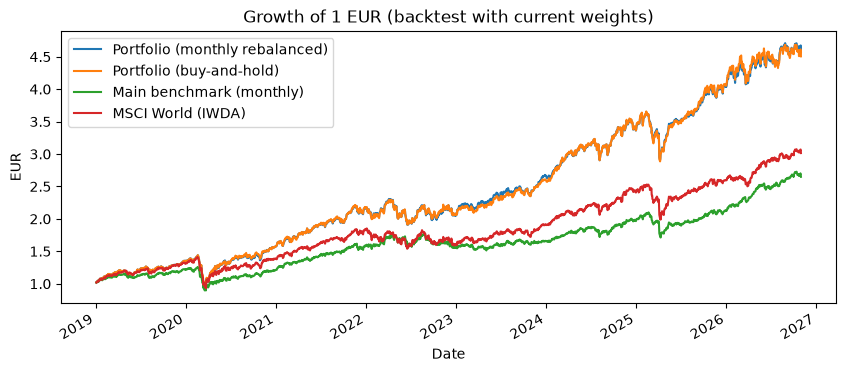

In [8]:
growth = (1 + series.dropna()).cumprod()
ax = growth.plot(figsize=(10, 4), title="Growth of 1 EUR (backtest with current weights)")
ax.set_ylabel("EUR")
plt.show()

## Performance metrics

In [9]:
def metrics(r, rf, bench=None):
    """Annualised performance and risk statistics of a daily return series."""
    r = r.dropna()
    rf = rf.reindex(r.index).fillna(0.0)
    excess = r - rf
    ann = np.sqrt(TRADING_DAYS)
    wealth = (1 + r).cumprod()
    downside = np.sqrt((excess.clip(upper=0) ** 2).mean()) * ann
    out = {
        "start": r.index.min().date(),
        "ann_return": wealth.iloc[-1] ** (TRADING_DAYS / len(r)) - 1,
        "ann_vol": r.std() * ann,
        "sharpe": excess.mean() * TRADING_DAYS / (r.std() * ann),
        "sortino": excess.mean() * TRADING_DAYS / downside,
        "max_drawdown": (wealth / wealth.cummax() - 1).min(),
    }
    if bench is not None:
        b = bench.reindex(r.index)
        both = pd.concat([r, b], axis=1).dropna()
        active = both.iloc[:, 0] - both.iloc[:, 1]
        tracking_error = active.std() * ann
        out["beta"] = both.cov().iloc[0, 1] / both.iloc[:, 1].var()
        out["tracking_error"] = tracking_error
        out["information_ratio"] = active.mean() * TRADING_DAYS / tracking_error
    return out

In [10]:
full = pd.DataFrame({
    name: metrics(series[name], rf, bench=bench_monthly if name.startswith("Portfolio") else None)
    for name in series.columns
}).T
full.round(3)

,start,ann_return,ann_vol,sharpe,sortino,max_drawdown,beta,tracking_error,information_ratio
Portfolio (monthly rebalanced),2019-01-04,0.208771,0.170512,1.130707,1.564771,-0.353229,0.998399,0.099973,0.733348
Portfolio (buy-and-hold),2019-01-04,0.206252,0.172461,1.10778,1.528814,-0.346542,0.991506,0.104531,0.684618
Main benchmark (monthly),2019-01-04,0.129001,0.138352,0.86363,1.177702,-0.286168,NaN,NaN,NaN
MSCI World (IWDA),2019-01-03,0.146343,0.165762,0.8381,1.164535,-0.339692,NaN,NaN,NaN


In [11]:
rows = {}
for label, (start, end) in SUBPERIODS.items():
    window = slice(start, end)
    rows[("Portfolio", label)] = metrics(port_monthly[window], rf, bench=bench_monthly[window])
    rows[("Benchmark", label)] = metrics(bench_monthly[window], rf)

subperiods = pd.DataFrame(rows).T
subperiods.round(3)

,,start,ann_return,ann_vol,sharpe,sortino,max_drawdown,beta,tracking_error,information_ratio
Portfolio,2019-2021,2019-01-04,0.284775,0.196744,1.401275,1.913106,-0.353229,1.074159,0.100701,1.071252
Benchmark,2019-2021,2019-01-04,0.161563,0.157726,1.063969,1.421862,-0.286168,NaN,NaN,NaN
Portfolio,2022,2022-01-03,-0.049346,0.202633,-0.148135,-0.207918,-0.172408,0.975536,0.124129,-0.206256
Benchmark,2022,2022-01-03,-0.017831,0.164231,-0.026881,-0.036975,-0.125525,NaN,NaN,NaN
Portfolio,2023-now,2023-01-02,0.226872,0.135678,1.370716,1.925015,-0.202606,0.892964,0.092086,0.782287
Benchmark,2023-now,2023-01-02,0.144975,0.112397,1.013713,1.422705,-0.18439,NaN,NaN,NaN


**Read with care.** Daily returns of a portfolio spread over US, European and Asian exchanges are not measured at the same moment (asynchronous closes, ECB fixing at 14:15 CET). This mostly biases **beta and correlations** towards zero. In notebook 05 (risk) we therefore also use weekly returns.

## Pies versus their look-through benchmark

Each pie is backtested on its own (monthly rebalanced) and compared with its benchmark from the first date both have data. AI Boom's benchmark (AIQU) only starts in September 2024, so that comparison is short.

In [12]:
pie_rows = {}
pie_series = {}
for pie, blend in PIE_BENCHMARKS.items():
    members = target[pie_of == pie]
    pie_ret = backtest(holding_returns, members, pie_of[members.index], month_ends(dates) + new_data_dates)
    blend_target = pd.Series(blend)
    blend_ret = backtest(returns_total, blend_target, pd.Series("blend", index=blend_target.index), month_ends(dates))
    common = pd.concat([pie_ret, blend_ret], axis=1).dropna().index
    pie_series[pie] = pie_ret
    stats = metrics(pie_ret[common], rf, bench=blend_ret[common])
    stats["bench_ann_return"] = metrics(blend_ret[common], rf)["ann_return"]
    pie_rows[pie] = stats

pie_table = pd.DataFrame(pie_rows).T
pie_table[["start", "ann_return", "bench_ann_return", "ann_vol", "sharpe", "max_drawdown", "beta", "tracking_error", "information_ratio"]].round(3)

,start,ann_return,bench_ann_return,ann_vol,sharpe,max_drawdown,beta,tracking_error,information_ratio
Kwaliteit,2019-01-04,0.171821,0.144083,0.172299,0.940146,-0.312346,0.73783,0.129827,0.194972
Thematisch,2019-01-04,0.178486,0.147349,0.244273,0.74797,-0.428856,1.223424,0.14108,0.304151
AI Boom,2024-09-18,0.376582,0.278895,0.303915,1.130897,-0.36761,0.736435,0.251036,0.354963
Energie,2019-01-04,0.234785,0.159849,0.216966,1.029217,-0.461973,0.628381,0.164968,0.287184
Mijnbouw,2019-01-04,0.215494,0.186698,0.2931,0.773269,-0.36954,0.768628,0.160824,0.070745
Multipolaire Wereldorde,2019-01-04,0.047318,0.090521,0.170565,0.289881,-0.397455,0.760808,0.096241,-0.466008


## Reconciliation with the Archief sheet

The workbook measures returns between month-end dates with closing prices (not total return) and adds a dividend correction: *pie return = weighted price return + dividend yield × duration*. Positions without a price at the start are left out and the pie is renormalised; pies are combined with target weights. The function below repeats that method in Python with the Yahoo data, so that differences come from the **data**, not the method.

In [13]:
def excel_style_return(returns_price, holdings, start, end):
    """Period return per pie and for the portfolio, using the workbook's method."""
    idx = returns_price.index
    t0 = idx[idx <= pd.Timestamp(start)].max()
    t1 = idx[idx <= pd.Timestamp(end)].max()
    window = returns_price.loc[(idx > t0) & (idx <= t1), holdings["ticker"]]
    period = (1 + window.fillna(0)).prod() - 1
    started = returns_price.loc[:t0, holdings["ticker"]].notna().any()
    years = (pd.Timestamp(end) - pd.Timestamp(start)).days / 365.25

    h = holdings.set_index("ticker")
    h = h.assign(period_return=period, started=started)
    h["total"] = h["period_return"] + h["dividend_yield"].fillna(0) * years
    used = h[h["started"]]
    pie_return = (used["total"] * used["weight_in_pie"]).groupby(used["pie"]).sum() / used.groupby("pie")["weight_in_pie"].sum()
    pie_target = holdings.groupby("pie")["weight_in_portfolio"].sum()
    pie_return["Portefeuille"] = (pie_return * pie_target).sum()
    return pie_return

In [14]:
archief_raw = pd.read_excel(DATA_PATH, sheet_name="Archief", header=None)
header_row = archief_raw.index[archief_raw[0] == "Periode"][0]
assert archief_raw.iat[header_row, 3] == "Portefeuille", "Archief layout changed"

PIE_COLUMNS = {}
for col in range(archief_raw.shape[1]):
    label = archief_raw.iat[header_row - 1, col]
    if label in PIE_BENCHMARKS:
        PIE_COLUMNS[label] = col
assert len(PIE_COLUMNS) == 6, f"Expected 6 pie columns, found {list(PIE_COLUMNS)}"

body = archief_raw.iloc[header_row + 1:]
is_period = (
    pd.to_numeric(body[3], errors="coerce").notna()
    & body[3].map(lambda v: not isinstance(v, bool))
    & ~body[0].astype(str).str.startswith("Geannualiseerd")
    & (pd.to_datetime(body[1], errors="coerce") < pd.to_datetime(body[2], errors="coerce"))
)
archief = body[is_period]
print(f"{len(archief)} periods with data:", list(archief[0]))

16 periods with data: ['Cumulatief sinds start', 'Juni 2026', 'Juli 2026', 'Augustus 2026', 'September 2026', 'Oktober 2026', 'Q3 2025', 'Q4 2025', 'Q1 2026', 'Q2 2026', 'Q3 2026', 'H1 2025', 'H2 2025', 'H1 2026', '2024', '2025']


In [15]:
recon_rows = []
for _, row in archief.iterrows():
    python = excel_style_return(returns_price, holdings, row[1], row[2])
    excel = {"Portefeuille": row[3], **{pie: row[col] for pie, col in PIE_COLUMNS.items()}}
    for name, excel_value in excel.items():
        recon_rows.append({
            "period": row[0],
            "begin": pd.Timestamp(row[1]).date(),
            "end": pd.Timestamp(row[2]).date(),
            "series": name,
            "excel": float(excel_value),
            "python": python[name],
        })

recon = pd.DataFrame(recon_rows)
recon["difference"] = recon["python"] - recon["excel"]
recon[recon["series"] == "Portefeuille"].round(4)

,period,begin,end,series,excel,python,difference
0,Cumulatief sinds start,2023-12-29,2026-10-31,Portefeuille,0.6338,0.6506,0.0168
7,Juni 2026,2026-05-29,2026-06-30,Portefeuille,0.0081,-0.0114,-0.0195
14,Juli 2026,2026-06-30,2026-07-31,Portefeuille,-0.0130,-0.0093,0.0037
21,Augustus 2026,2026-07-31,2026-08-31,Portefeuille,0.0595,0.0592,-0.0003
28,September 2026,2026-08-31,2026-09-30,Portefeuille,-0.0223,-0.0227,-0.0004
35,Oktober 2026,2026-09-30,2026-10-31,Portefeuille,0.0070,0.0061,-0.0009
42,Q3 2025,2025-06-30,2025-09-30,Portefeuille,0.0973,0.0945,-0.0028
49,Q4 2025,2025-09-30,2025-12-31,Portefeuille,0.0490,0.0450,-0.0040
56,Q1 2026,2025-12-31,2026-03-31,Portefeuille,0.0433,0.0308,-0.0125
63,Q2 2026,2026-03-31,2026-06-30,Portefeuille,0.0563,0.0753,0.0189


In [16]:
recon.pivot_table(index="series", columns="period", values="difference", sort=False).round(4)

period,Cumulatief sinds start,Juni 2026,Juli 2026,Augustus 2026,September 2026,Oktober 2026,Q3 2025,Q4 2025,Q1 2026,Q2 2026,Q3 2026,H1 2025,H2 2025,H1 2026,2024,2025
series,,,,,,,,,,,,,,,,
Portefeuille,0.0168,-0.0195,0.0037,-0.0003,-0.0004,-0.0009,-0.0028,-0.0040,-0.0125,0.0189,0.0041,0.0060,-0.0057,0.0079,0.0008,0.0058
Kwaliteit,-0.0003,-0.0166,0.0016,0.0012,-0.0005,-0.0010,0.0014,0.0056,-0.0206,0.0144,0.0023,0.0003,0.0065,-0.0081,-0.0077,0.0067
Thematisch,-0.0016,0.0066,-0.0105,0.0136,-0.0101,-0.0000,-0.0193,0.0041,-0.0213,0.0503,-0.0074,-0.0035,-0.0104,0.0241,0.0024,-0.0145
AI Boom,-0.0115,0.0062,-0.0082,-0.0000,0.0000,-0.0046,-0.0000,-0.0272,0.0096,0.0377,-0.0082,-0.0000,-0.0335,0.0641,-0.0000,-0.0335
Energie,0.0114,0.0191,-0.0017,-0.0120,0.0095,-0.0018,-0.0002,-0.0227,0.0331,0.0070,-0.0043,0.0003,-0.0254,0.0367,0.0059,-0.0302
Mijnbouw,0.1055,-0.1102,0.0334,0.0006,-0.0007,-0.0017,0.0003,0.0148,-0.0564,0.0044,0.0404,0.0362,0.0258,-0.0447,0.0084,0.0990
Multipolaire Wereldorde,-0.0115,-0.0078,0.0008,-0.0023,-0.0037,0.0028,-0.0045,-0.0118,-0.0101,0.0183,-0.0057,0.0011,-0.0170,0.0099,0.0006,-0.0147


**Expected sources of difference** (to be confirmed per row):
1. **Price source**: Yahoo versus manually entered Trading212 prices, including different listings (EW on NYSE instead of Xetra, Assa Abloy in Stockholm instead of OTC, HBM on TSX instead of NYSE, alternative lines for several ETFs).
2. **Coverage**: Yahoo has EW before 2024, the workbook does not; the workbook treats a missing price as 0, Python as `NaN`.
3. **Proxies**: EPIN before February 2026 is the US fund EPI in Python and a CFD in the workbook.
4. **Dates**: a weekend month-end (for example 31-10-2026) uses the last trading day in Python.

## Real returns

The thesis is about purchasing power, so returns are also shown after euro-area inflation (HICP, monthly index from the ECB). Wealth at each month-end is divided by the price level of that month relative to December 2018. Cash earns €STR. HICP is published with a lag of a few weeks, so the last month(s) may be missing.

In [17]:
hicp_raw = pd.read_csv(HICP_URL)
hicp = hicp_raw.set_index(pd.PeriodIndex(hicp_raw["TIME_PERIOD"], freq="M"))["OBS_VALUE"].sort_index()

monthly_wealth = (1 + series.assign(**{"Cash (€STR)": rf})).cumprod().resample("ME").last()
monthly_wealth.index = monthly_wealth.index.to_period("M")
months = monthly_wealth.index.intersection(hicp.index)
print(f"HICP from {hicp.index.min()} to {hicp.index.max()}; real returns up to {months.max()}")


def real_returns(start_month, end_month):
    """Annualised nominal, inflation and real return between two month-ends."""
    start, end = pd.Period(start_month, "M"), pd.Period(end_month, "M")
    window = [m for m in months if start <= m <= end]
    first, last = window[0], window[-1]
    base_wealth = monthly_wealth.loc[first - 1] if first - 1 in monthly_wealth.index else 1.0
    n_years = (len(window)) / 12
    nominal = monthly_wealth.loc[last] / base_wealth
    inflation = hicp.loc[last] / hicp.loc[first - 1]
    return pd.DataFrame({
        "nominal": nominal ** (1 / n_years) - 1,
        "inflation": inflation ** (1 / n_years) - 1,
        "real": (nominal / inflation) ** (1 / n_years) - 1,
    })

HICP from 2018-12 to 2025-12; real returns up to 2025-12


In [18]:
real_full = real_returns("2019-01", str(months.max()))
real_full.round(4)

,nominal,inflation,real
Portfolio (monthly rebalanced),0.2204,0.0318,0.1828
Portfolio (buy-and-hold),0.2214,0.0318,0.1838
Main benchmark (monthly),0.1134,0.0318,0.0791
MSCI World (IWDA),0.1450,0.0318,0.1097
Cash (€STR),0.0107,0.0318,-0.0204


In [19]:
real_rows = []
for label, (start, end) in SUBPERIODS.items():
    end_month = min(pd.Period(end[:7], "M"), months.max())
    table = real_returns(start[:7], str(end_month)).assign(period=label)
    real_rows.append(table.reset_index(names="series"))

real_sub = pd.concat(real_rows, ignore_index=True)
real_sub.pivot_table(index="series", columns="period", values="real", sort=False).round(4)

period,2019-2021,2022,2023-now
series,,,
Portfolio (monthly rebalanced),0.2677,-0.1305,0.2228
Portfolio (buy-and-hold),0.2694,-0.1308,0.2237
Main benchmark (monthly),0.1432,-0.1009,0.0825
MSCI World (IWDA),0.1982,-0.2037,0.1480
Cash (€STR),-0.0250,-0.0843,0.0065


## Export

In [20]:
backtest_long = series.stack().dropna().rename("return").reset_index()
backtest_long.columns = ["date", "series", "return"]

pie_long = pd.DataFrame(pie_series).stack().dropna().rename("return").reset_index()
pie_long.columns = ["date", "pie", "return"]

with sqlite3.connect(DB_PATH) as con:
    backtest_long.to_sql("backtest_returns", con, if_exists="replace", index=False)
    pie_long.to_sql("pie_returns", con, if_exists="replace", index=False)
    full.reset_index(names="series").astype(str).to_sql("performance_full", con, if_exists="replace", index=False)
    real_full.reset_index(names="series").to_sql("real_returns", con, if_exists="replace", index=False)

series.to_parquet(PROCESSED_DIR / "backtest_returns.parquet")
pd.DataFrame(pie_series).to_parquet(PROCESSED_DIR / "pie_returns.parquet")
recon.to_parquet(PROCESSED_DIR / "archief_reconciliation.parquet")
real_full.reset_index(names="series").to_parquet(PROCESSED_DIR / "real_returns.parquet", index=False)
"exported"

'exported'